# Connectome Spectrum Transform from a template

If the patient's tractography is unavailable, you can infer a structural connectome using a connectome atlas. In this project, we use the MultiConn atlas from [Alemán-Gómez et. al 2022](https://www.nature.com/articles/s41597-022-01624-8).

The connectome in this context represents the structural connections between sources in our source space. These include white matter tracts (long-range connections) inferred from an atlas, and gray matter tracts (short-range connections) inferred from a specific method.

- **White Matter Tracts**: Two sources are connected if the brain regions they belong to are connected according to the MultiConn atlas. This requires segmenting the subject's brain using MultiConn's parcellation, which was done in `./parcellation.ipynb`. The parcellation results are stored in `../dataset/spike_sample/derivatives/mindmap/subject/parc/`.
- **Gray Matter Tracts**: Two sources are connected if their geodesic distance is smaller than a user-defined threshold.

Once the connectome for the source space is obtained, the Connectome Spectrum Transform is performed by computing the graph signal transform of the connectome.

The following process is available in `mindmap.prior.compute_cst_from_template(...)`.

## Imports

In [1]:
#%matplotlib qt 

import mindmap as mm
from pathlib import Path
import mne
import matplotlib.pyplot as plt 
import numpy as np
import pygsp
import nibabel as nib
import h5py
import scipy as sp

config = mm.io.read_config("../configurations/spike.yml")
mm_dir = Path(config["MM_DIR"])
fs_dir = Path(config["FS_DIR"])

## Data

In [56]:
subject = "sub-pat21"
scale   = 4

# files
sources = mm_dir/subject/"src"/f"{subject}_ddm-surf-7-src.fif"
T1      = fs_dir/subject/"mri"/"T1.mgz"
parcel  = mm_dir/subject/"parc"/f"{subject}_multiConn{scale}-2-0.05_dparc.nii.gz"
clut    = mm_dir/subject/"parc"/f"{subject}_multiConn{scale}-2-0.05_clut.txt"
atlas   = f'/home/admin/work/data/atlas/probconnatlas/wm.connatlas.scale{scale}.h5'
whitelh = fs_dir/subject/"surf"/"lh.white"
whiterh = fs_dir/subject/"surf"/"rh.white"

# parameters
cons_thresh = 40       # consistency threshold
len_thresh  = 25       # fiber length threshold
n_thresh    = 20       # number of streamlines threshold
dmax        = 0.010    # maximum distance for short distance connection

# load
sources = mne.read_source_spaces(sources)
T1      = nib.load(T1)
torig   = T1.header.get_vox2ras_tkr()
parcel  = mm.utils.Parcellation(parcel, clut)
atlas   = h5py.File(atlas)
whitelh = nib.freesurfer.io.read_geometry(whitelh)
whiterh = nib.freesurfer.io.read_geometry(whiterh)

    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    2 source spaces read


## Atlas White Matter Tracts

In [57]:
import pandas as pd 

def correct_labels(labels, sources, parcel):
    # map to switch from label id to label name
    clut = parcel.get_clut()
    map  = pd.Series(clut["Label name"].values, index=clut["#No."]).to_dict()
    
    label_names = [map[id] for id in labels]

    # left/right hemisphere seperation
    split = len(sources[0]["vertno"])

    # switch 'lh' labels in right hemisphere to 'rh' homologue and vice virsa
    label_names[:split] = [l.replace("-rh-", "-lh-") for l in label_names[:split]]
    label_names[split:] = [l.replace("-lh-", "-rh-") for l in label_names[split:]]

    # convert back to lable ids
    new_labels = [list(map.keys())[list(map.values()).index(n)] for n in label_names]

    return new_labels

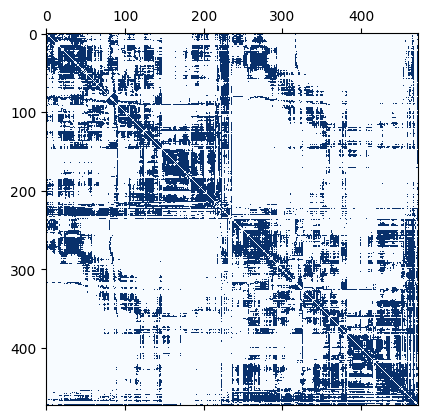

In [58]:
# label sources
points = [s["rr"][s["vertno"]] for s in sources]
points = np.concatenate(points)*1000                # in surface RAS space in [mm].
labels = parcel.get_ids(points, parcel.get_nifti().affine)              # brain region label for each source.

# some left/right regions are very close and get mixed up
labels = correct_labels(labels, sources, parcel)

# convert atlas to binary adjacency matrix
consistency = atlas["matrices"]["consistency"]
length      = atlas["matrices"]["length"]
number      = atlas["matrices"]["numbStlines"]

sc_atlas = np.bitwise_and(
    consistency[:,:] > cons_thresh, 
    length[:,:] > len_thresh,
    number[:,:] > n_thresh,
)

_ = plt.matshow(sc_atlas, cmap="Blues")

## Subject White Matter Tracts

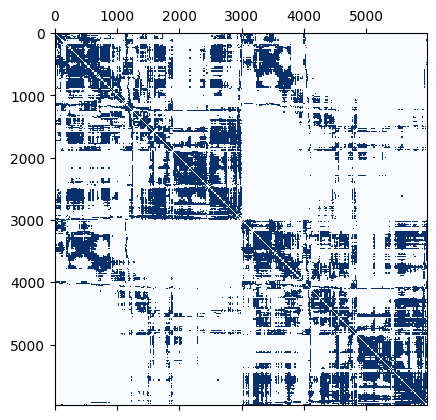

In [59]:
# create connections between sources
# (if source A belongs to a region that is connected to the region of source B, then connect both sources.)
N = points.shape[0]
sc = np.zeros((N,N))

for i, l in enumerate(labels):
    connected_regions = np.argwhere(sc_atlas[l-1]==1)+1
    connections = np.isin(labels, connected_regions)
    sc[i] = connections 

sc = sp.sparse.csc_array(sc>0)

# sort for plotting
idx = np.argsort(labels)
viz = sc.todense()[idx]
viz = viz[:,idx]
_   = plt.matshow(viz, cmap="Blues")

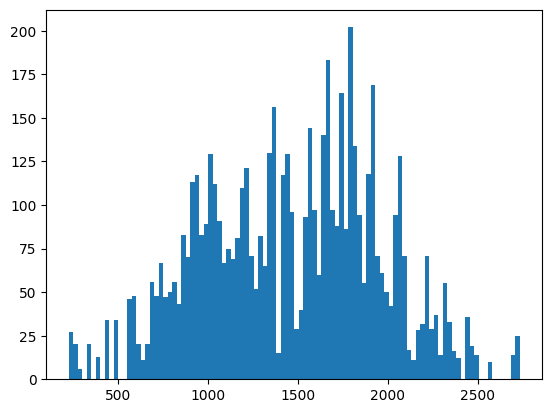

In [60]:
degrees = sc.sum(axis=1)
_ = plt.hist(degrees, bins=100)

## Gray Matter Tracts

In [61]:
gmt = mm.utils.interpol_gm_tracks(sources, dmax)

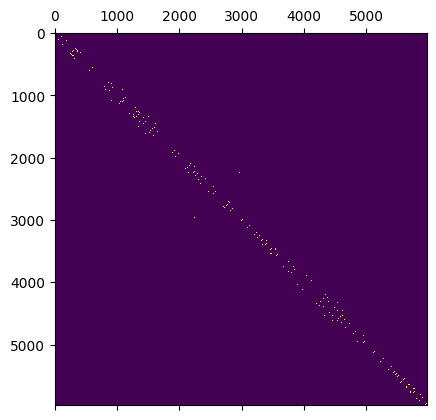

In [62]:
_ = plt.matshow(gmt.todense())

Number of sources without gray matter connections:  0


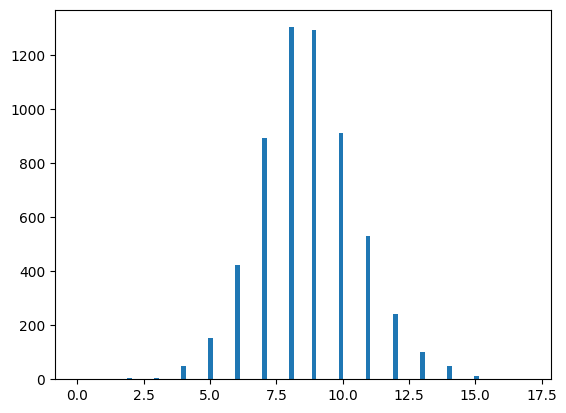

In [63]:
degrees = gmt.sum(axis=1)
print("Number of sources without gray matter connections: ", np.sum(degrees<0))
_ = plt.hist(degrees, bins=100)

#### Whole connectome

In [64]:
sc = sc + gmt 
sc = sc.astype(bool).astype(int)

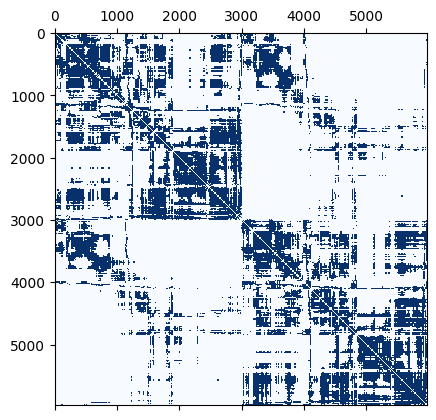

In [65]:
idx = np.argsort(labels)
viz = sc.todense()[idx]
viz = viz[:,idx]
_ = plt.matshow(viz, cmap="Blues")

Number of sources without connections:  0


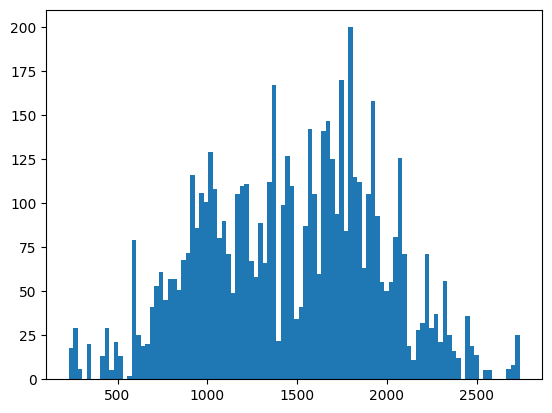

In [66]:
degrees = sc.sum(axis=1)
print("Number of sources without connections: ", np.sum(degrees<0))
_ = plt.hist(degrees, bins=100)

#### Connectome Spectrum Transform

In [67]:
# (30 s)
coords = [s["rr"][s["vertno"]] for s in sources]
G = pygsp.graphs.Graph(sc.todense(), lap_type="normalized", coords=coords)
G.compute_fourier_basis()
cst = G.U.T

2024-09-24 17:58:37,003:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (5972 x 5972) may take some time.


In [70]:
harmonic = cst[3,:]
mm.viz.plot_brain_signal(sources, harmonic).show()

Widget(value='<iframe src="http://localhost:45211/index.html?ui=P_0x7fed8569d940_8&reconnect=auto" class="pyvi…

In [17]:
folder = mm_dir/subject/"cst"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving connectome template for subject: {subject}")
np.save(folder/f"{subject}_cst-template.npy", cst)

Saving connectome template for subject: sub-pat09
